# Can You Tell a Valorant Player's Role From Their Stats?
Pranav Meka · Portfolio Project 1 · CU Boulder

## 1. The Dataset

Every Valorant agent belongs to one of four roles:

| Role | Job on the team |
|---|---|
| Duelist | Take the first fight and create space |
| Initiator | Gather info and set up teammates (flashes, recon) |
| Controller | Smoke off vision and control the map |
| Sentinel | Hold sites, watch flanks, slow pushes |

The data is pro match stats from the 2026 Valorant Champions Tour, from the Kaggle dataset Valorant Champion Tour 2021-2026 Data (`players_stats.csv`). Each row is one player's stats on one agent during one stage of a tournament: kills, deaths, assists, first kills, headshot %, damage per round, etc.

Question: if I hide the agent, can a model figure out the player's role from their numbers alone?

Why I care: I play Valorant and have always felt that role shapes a stat line. Duelists should die first more, controllers should get more assists. I wanted to see if that holds up in pro play.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, f1_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ROLE_ORDER = ["duelist", "initiator", "controller", "sentinel"]

raw = pd.read_csv("players_stats.csv")
print(raw.shape)
raw.head()

(11821, 25)


,Tournament,Stage,Match Type,Player,Teams,Agents,Rounds Played,Rating,Average Combat Score,Kills:Deaths,...,First Deaths Per Round,Headshot %,Clutch Success %,Clutches (won/played),Maximum Kills in a Single Map,Kills,Deaths,Assists,First Kills,First Deaths
0,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,astra,26,1.27,204,1.36,...,0.08,23%,20%,1/5,19,19,14,12,0,2
1,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,cypher,18,1.14,192,1.56,...,0.06,28%,100%,1/1,14,14,9,3,2,1
2,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,omen,17,0.84,131,0.73,...,0.12,29%,NaN,0/3,8,8,11,2,2,2
3,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,CHICHOO,EDward Gaming,"astra, cypher, omen",61,1.11,176,1.21,...,0.08,26%,22%,2/9,19,41,34,17,4,5
4,Valorant Masters London 2026,Playoffs,Upper Quarterfinals,Jieni7,EDward Gaming,brimstone,18,1.39,187,1.63,...,0.00,31%,NaN,0/1,13,13,8,8,0,0


In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11821 entries, 0 to 11820
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Tournament                      11821 non-null  object 
 1   Stage                           11821 non-null  object 
 2   Match Type                      11821 non-null  object 
 3   Player                          11821 non-null  object 
 4   Teams                           11821 non-null  object 
 5   Agents                          11821 non-null  object 
 6   Rounds Played                   11821 non-null  int64  
 7   Rating                          11630 non-null  float64
 8   Average Combat Score            11821 non-null  int64  
 9   Kills:Deaths                    11821 non-null  float64
 10  Kill, Assist, Trade, Survive %  11638 non-null  object 
 11  Average Damage Per Round        11642 non-null  float64
 12  Kills Per Round                 

### First cleanup

Two kinds of rows have to go:

1. "All Match Types" rows are totals of the other rows, so keeping them double counts games.
2. Rows with more than one agent (e.g. `"fade, sova"`) mix stats across agents and sometimes across roles, so there's no single correct label.

Then I map each agent to its role, which is the target y.

In [3]:
df = raw[raw["Match Type"] != "All Match Types"].copy()
df = df[~df["Agents"].str.contains(",")]

ROLES = {
    "duelist":    ["jett", "raze", "reyna", "phoenix", "yoru", "neon", "iso", "waylay"],
    "initiator":  ["sova", "breach", "skye", "kayo", "fade", "gekko", "tejo"],
    "controller": ["brimstone", "viper", "omen", "astra", "harbor", "clove"],
    "sentinel":   ["killjoy", "cypher", "sage", "chamber", "deadlock", "vyse", "veto"],
}
agent_to_role = {agent: role for role, agents in ROLES.items() for agent in agents}
df["Role"] = df["Agents"].map(agent_to_role)

print("Agents with no known role:", df.loc[df["Role"].isna(), "Agents"].unique())
df = df.dropna(subset=["Role"])   # drops 1 row for an agent I couldn't confirm the role of
print("Rows after cleanup:", len(df), "(from", len(raw), ")")

Agents with no known role: ['miks']
Rows after cleanup: 6481 (from 11821 )


### Converting text columns to numbers

Some stats are stored as text, like `"23%"` or `"1/5"`. I:

- Strip the `%` from percentage columns.
- Turn `Clutches (won/played)` into Clutches Played Per Round, i.e. how often a player ends up last alive.
- Add Opening Duels Per Round = first kills + first deaths per round, which measures how often a player is in the first fight, win or lose.

In [4]:
for col in ["Kill, Assist, Trade, Survive %", "Headshot %", "Clutch Success %"]:
    df[col] = df[col].str.rstrip("%").astype(float)

clutch = df["Clutches (won/played)"].str.split("/", expand=True).astype(float)
df["Clutches Played Per Round"] = clutch[1] / df["Rounds Played"]
df["Opening Duels Per Round"] = df["First Kills Per Round"] + df["First Deaths Per Round"]

df = df.rename(columns={"Kill, Assist, Trade, Survive %": "KAST %"})

### Choosing features

I only use per-round stats and percentages. Raw totals like `Kills` mostly reflect how many rounds someone played, not their role.

I leave out `Player`, `Teams`, and `Tournament`. Pros mostly stick to one role, so with names the model could just memorize who plays what.

`Stage` is the only text field I keep, to see if stats shift in bigger matches.

In [5]:
NUMERIC = ["Rating", "Average Combat Score", "Kills:Deaths", "KAST %", "Average Damage Per Round",
           "Kills Per Round", "Assists Per Round", "First Kills Per Round", "First Deaths Per Round",
           "Headshot %", "Clutch Success %", "Clutches Played Per Round", "Opening Duels Per Round"]
CATEGORICAL = ["Stage"]

data = df[NUMERIC + CATEGORICAL + ["Rounds Played", "Player", "Role"]].reset_index(drop=True)
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Rating,6353.0,1.00,0.31,0.03,0.79,0.98,1.19,2.81
Average Combat Score,6481.0,196.05,53.62,38.00,159.00,192.00,229.00,516.00
Kills:Deaths,6481.0,1.06,0.52,0.08,0.75,1.00,1.27,13.00
KAST %,6358.0,71.35,10.76,25.00,65.00,71.00,78.00,100.00
Average Damage Per Round,6361.0,128.78,33.88,34.00,106.00,127.00,150.00,353.00
Kills Per Round,6481.0,0.69,0.21,0.07,0.55,0.68,0.82,2.00
Assists Per Round,6481.0,0.28,0.15,0.00,0.17,0.25,0.36,1.19
First Kills Per Round,6361.0,0.10,0.07,0.00,0.05,0.09,0.14,0.53
First Deaths Per Round,6361.0,0.10,0.07,0.00,0.05,0.09,0.14,0.71
Headshot %,6357.0,28.70,9.36,4.00,22.00,28.00,34.00,73.00


## 2. Feature Engineering

### 2a. Class (im)balance

Role
duelist       0.292
initiator     0.247
controller    0.316
sentinel      0.145
Name: count, dtype: float64


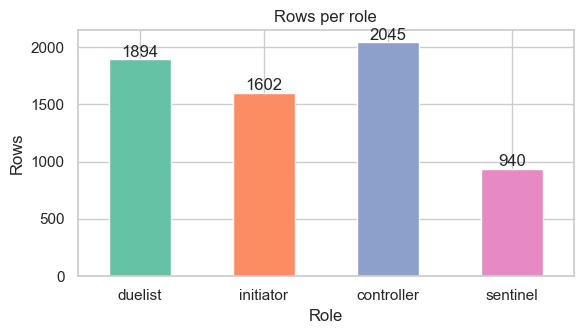

In [6]:
counts = data["Role"].value_counts().reindex(ROLE_ORDER)
print((counts / counts.sum()).round(3))

ax = counts.plot(kind="bar", color=sns.color_palette("Set2", 4), figsize=(6, 3.5), rot=0)
ax.set_title("Rows per role"); ax.set_ylabel("Rows")
for i, v in enumerate(counts): ax.text(i, v + 20, v, ha="center")
plt.tight_layout(); plt.show()

The classes are moderately imbalanced: sentinels are about 15% of rows and controllers about 31%. That fits how pro teams draft, often two controllers or two initiators but rarely two sentinels.

So:
- Accuracy alone could hide a model that ignores sentinels, so I also report per-class recall and F1.
- I train with `class_weight="balanced"` so mistakes on smaller classes cost more.

### 2b. Feature histograms and outliers

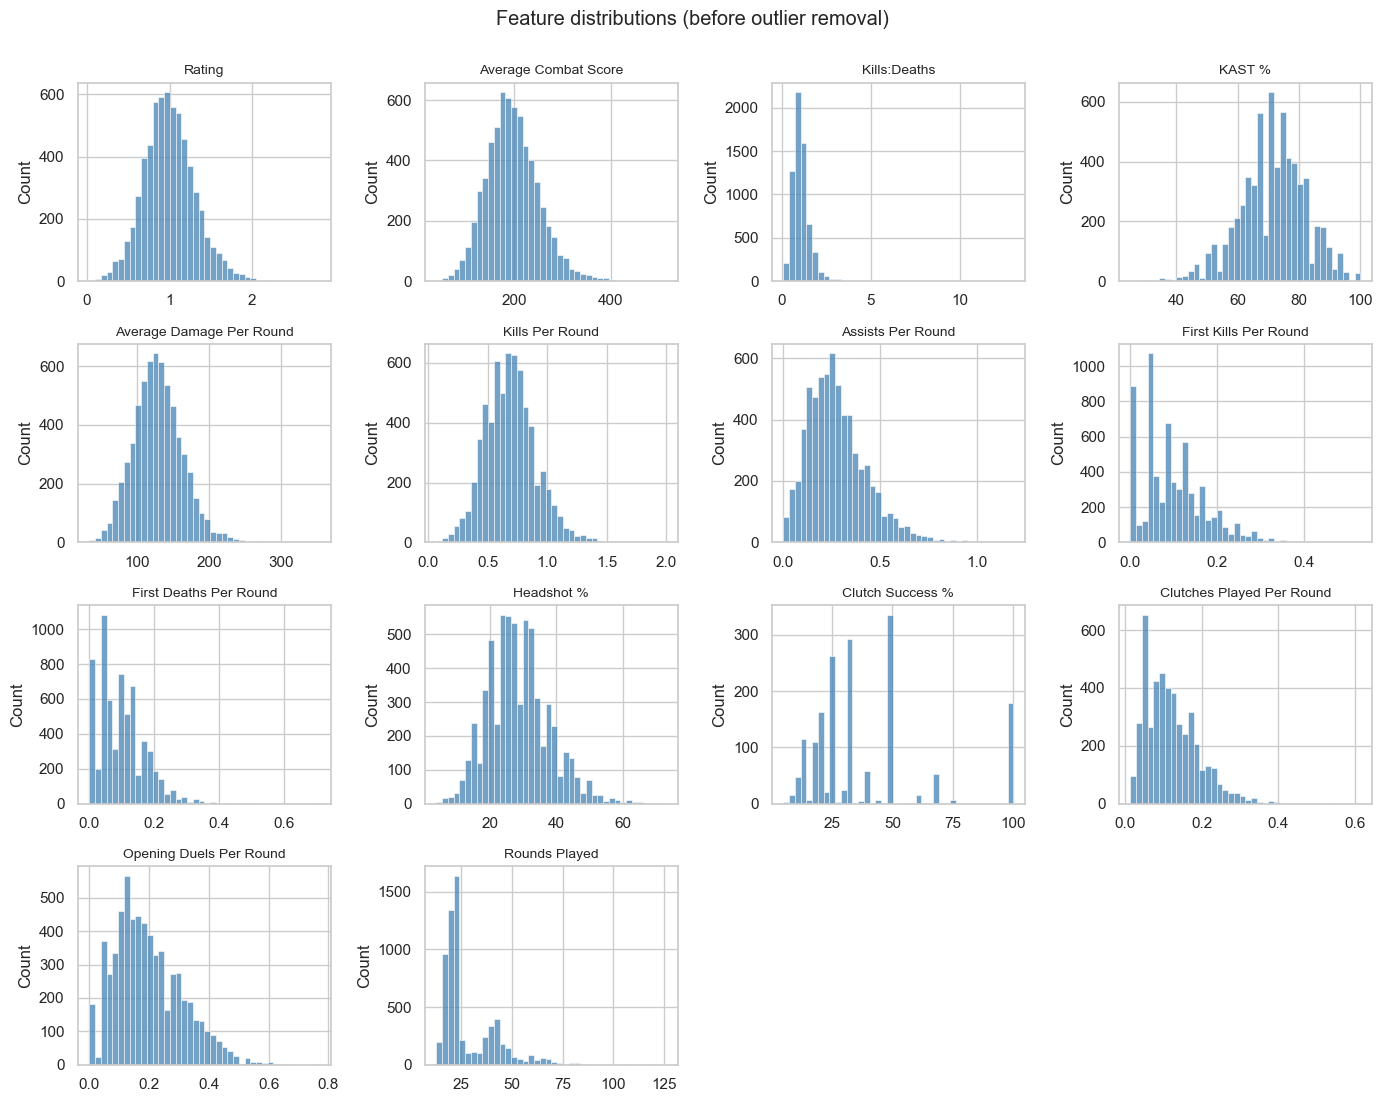

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 11))
for ax, col in zip(axes.flat, NUMERIC + ["Rounds Played"]):
    sns.histplot(data[col].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.flat[len(NUMERIC) + 1:]: ax.remove()
plt.suptitle("Feature distributions (before outlier removal)", y=1.0)
plt.tight_layout(); plt.show()

- Most features are roughly bell-shaped, which is fine for logistic regression.
- Kills:Deaths has a long right tail, with a few K:D values around 13. These are players with very few deaths over few rounds, so it's sample size, not skill.
- Rounds Played starts at 13 and is right-skewed. Fewer rounds means noisier per-round stats.

For outliers I use a 3 × IQR fence instead of the usual 1.5 ×. The tighter rule would cut real role signal, like duelists' high first-kill rates, which is exactly what the model needs. 3 × IQR only drops the extreme cases.

In [8]:
OUTLIER_COLS = ["Kills:Deaths", "Kills Per Round", "Assists Per Round", "First Kills Per Round",
                "First Deaths Per Round", "Average Damage Per Round", "Headshot %"]

def iqr_mask(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s.isna() | s.between(q1 - k * iqr, q3 + k * iqr)   # keep missing values; they're handled in 2c

keep = np.logical_and.reduce([iqr_mask(data[c]) for c in OUTLIER_COLS])
removed = data.loc[~keep]
print(f"Removed {len(removed)} rows ({len(removed)/len(data):.1%})")
print("Removed rows by role:", removed["Role"].value_counts().to_dict())
print("Median rounds played, removed vs kept:",
      removed["Rounds Played"].median(), "vs", data.loc[keep, "Rounds Played"].median())

data = data.loc[keep].reset_index(drop=True)

Removed 83 rows (1.3%)
Removed rows by role: {'controller': 31, 'initiator': 25, 'duelist': 17, 'sentinel': 10}
Median rounds played, removed vs kept: 16.0 vs 23.0


The removed rows have fewer rounds than average, so they look like small-sample flukes. They're spread across all roles, so no class loses much.

### 2c. Imputing missing values

In [9]:
missing = data[NUMERIC].isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = (missing["missing"] / len(data) * 100).round(1)
missing

,missing,percent
Rating,128,2.0
KAST %,123,1.9
Average Damage Per Round,120,1.9
First Kills Per Round,120,1.9
First Deaths Per Round,120,1.9
Headshot %,124,1.9
Clutch Success %,4706,73.6
Clutches Played Per Round,1813,28.3
Opening Duels Per Round,120,1.9


There are two kinds of missing data, so I handle them differently:

| Column(s) | Why it's missing | What I do |
|---|---|---|
| Clutch Success % | Over half the rows, since there's no success rate without clutch attempts | Drop the column |
| Clutches Played Per Round | Blank clutch record means no clutches | Fill with 0 |
| Rating, KAST %, ADR, First Kills/Deaths, Headshot % | About 2% of rows the source didn't record | Fill with the role's median |

I fill by role because a duelist's median first-kill rate is very different from a controller's, and one overall median would pull everyone toward the middle.

Note on leakage: ideally the imputer would only see training data, and filling by role uses the label. Since only about 2% of values are filled, the effect is tiny here, but in a real project I'd fit imputation on the training split only.

In [10]:
data = data.drop(columns=["Clutch Success %"])
NUMERIC.remove("Clutch Success %")

data["Clutches Played Per Round"] = data["Clutches Played Per Round"].fillna(0)

for col in NUMERIC:
    data[col] = data.groupby("Role")[col].transform(lambda s: s.fillna(s.median()))

# Opening Duels depends on First Kills/Deaths, so rebuild it after filling those in
data["Opening Duels Per Round"] = data["First Kills Per Round"] + data["First Deaths Per Round"]

print("Missing values left:", int(data[NUMERIC].isna().sum().sum()))

Missing values left: 0


### 2d. Encoding text fields

- Stage has no natural order, so I one-hot encode it.
- Role is the target. I leave it as text since scikit-learn handles string labels and it keeps the confusion matrix readable.

In [11]:
data = pd.get_dummies(data, columns=["Stage"], prefix="Stage", dtype=int)
STAGE_COLS = [c for c in data.columns if c.startswith("Stage_")]
print(STAGE_COLS)
data[STAGE_COLS].head()

['Stage_Group Stage', 'Stage_Main Event', 'Stage_Playoffs', 'Stage_Swiss Stage']


,Stage_Group Stage,Stage_Main Event,Stage_Playoffs,Stage_Swiss Stage
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


### 2e. Correlated columns

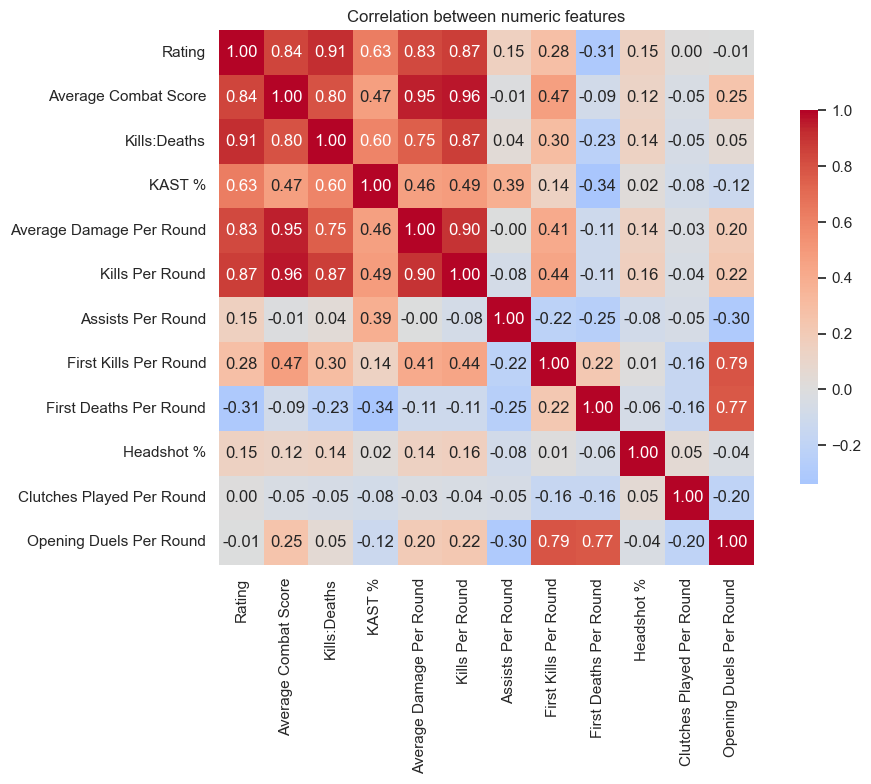

In [12]:
plt.figure(figsize=(11, 8))
corr = data[NUMERIC].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation between numeric features")
plt.tight_layout(); plt.show()

In [13]:
THRESHOLD = 0.90
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > THRESHOLD].sort_values(ascending=False)
print("Highly correlated pairs (|r| > 0.90):")
print(pairs.round(3))

Highly correlated pairs (|r| > 0.90):
Average Combat Score      Kills Per Round             0.964
                          Average Damage Per Round    0.951
Rating                    Kills:Deaths                0.913
Average Damage Per Round  Kills Per Round             0.902
dtype: float64


Two groups of columns are near-duplicates:

- ACS, ADR and Kills Per Round measure almost the same thing, since ACS is mostly built from damage and kills. I keep Kills Per Round and drop the other two.
- Rating and Kills:Deaths have a correlation of 0.91, and Rating is a summary of other stats anyway. I keep Kills:Deaths.

Duplicate columns add nothing and make coefficients harder to read, since the model can split one effect between them.

Opening Duels Per Round overlaps with first kills and first deaths, but I keep it because it captures involvement in the first fight, and regularization handles the overlap.

In [14]:
TO_DROP = ["Average Combat Score", "Average Damage Per Round", "Rating"]
FEATURES = [c for c in NUMERIC if c not in TO_DROP] + STAGE_COLS
print(len(FEATURES), "features:", FEATURES)

13 features: ['Kills:Deaths', 'KAST %', 'Kills Per Round', 'Assists Per Round', 'First Kills Per Round', 'First Deaths Per Round', 'Headshot %', 'Clutches Played Per Round', 'Opening Duels Per Round', 'Stage_Group Stage', 'Stage_Main Event', 'Stage_Playoffs', 'Stage_Swiss Stage']


## 3. Looking for Clusters (without using y)

Before training, I check if the data forms natural groups without the labels. If the clusters match roles, roles leave a clear mark on the stats.

I scale the numeric features (no Stage) and run K-Means for k = 2 to 8.

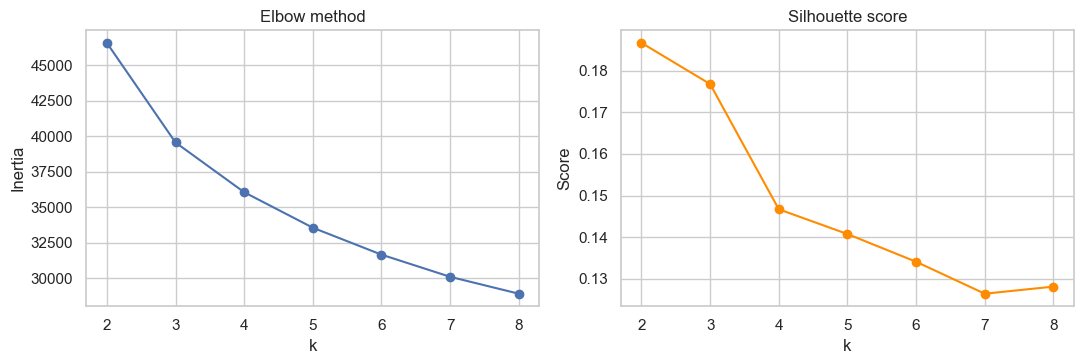

{2: np.float64(0.187), 3: np.float64(0.177), 4: np.float64(0.147), 5: np.float64(0.141), 6: np.float64(0.134), 7: np.float64(0.126), 8: np.float64(0.128)}


In [15]:
STAT_FEATURES = [c for c in FEATURES if not c.startswith("Stage_")]
X_scaled = StandardScaler().fit_transform(data[STAT_FEATURES])

ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ks, inertias, "o-"); a1.set(title="Elbow method", xlabel="k", ylabel="Inertia")
a2.plot(ks, silhouettes, "o-", color="darkorange"); a2.set(title="Silhouette score", xlabel="k", ylabel="Score")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(silhouettes, 3))))

There's no clear elbow and the silhouette scores are low, so the data is one continuous cloud rather than separate groups.

Since there are four roles, I use k = 4 and check if the clusters line up with them anyway.

Variance explained by 2 PCA components: 0.568


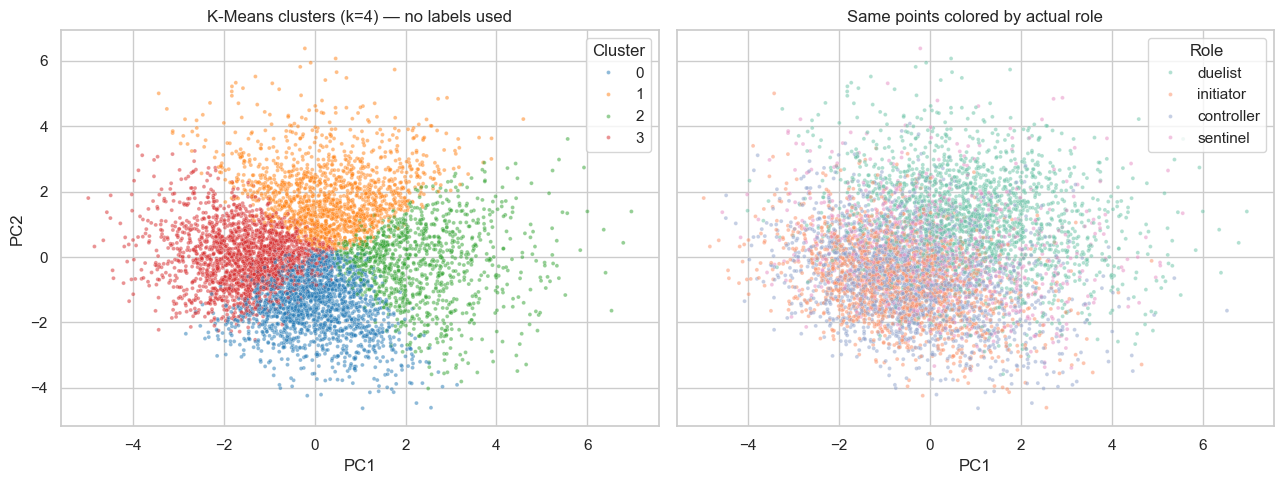

In [16]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
data["Cluster"] = km4.labels_

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
print("Variance explained by 2 PCA components:", pca.explained_variance_ratio_.sum().round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Cluster"], palette="tab10", s=8, alpha=.5, ax=a1, legend="full")
a1.set(title="K-Means clusters (k=4) — no labels used", xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Role"], hue_order=ROLE_ORDER, palette="Set2", s=8, alpha=.5, ax=a2)
a2.set(title="Same points colored by actual role", xlabel="PC1")
plt.tight_layout(); plt.show()

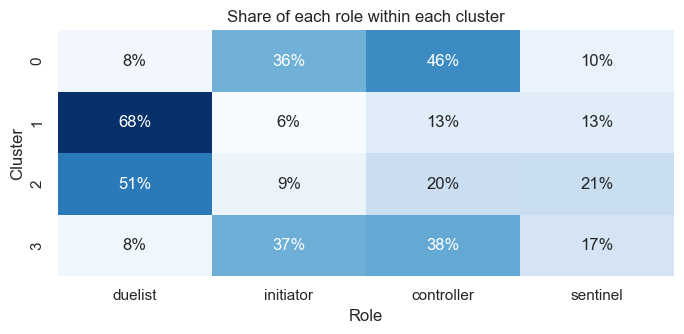

Cluster,0,1,2,3
Kills:Deaths,1.21,0.87,1.57,0.72
KAST %,78.86,65.25,78.25,64.68
Kills Per Round,0.73,0.65,0.96,0.52
Assists Per Round,0.39,0.20,0.22,0.25
First Kills Per Round,0.06,0.14,0.18,0.05
First Deaths Per Round,0.06,0.18,0.09,0.08
Headshot %,29.21,27.50,30.95,27.75
Clutches Played Per Round,0.08,0.06,0.08,0.12
Opening Duels Per Round,0.12,0.32,0.27,0.13


In [17]:
ct = pd.crosstab(data["Cluster"], data["Role"], normalize="index").reindex(columns=ROLE_ORDER)
plt.figure(figsize=(7, 3.5))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Share of each role within each cluster"); plt.tight_layout(); plt.show()

# What each cluster looks like on average (in original units)
data.groupby("Cluster")[STAT_FEATURES].mean().round(2).T

What the clusters show (numbers match the tables above):

| Cluster | Stat profile | Main roles |
|---|---|---|
| 1 | Most opening duels, more first deaths than first kills | 68% duelists |
| 2 | Highest kills/round, K:D and first kills | 51% duelists |
| 0 | Most assists, high KAST, rarely in the first fight | 82% initiators + controllers |
| 3 | Fewest kills, lowest K:D, most clutches | 75% initiators + controllers |

Without labels, K-Means still found an entry vs. support split. Duelists stand out because they take the first fight, often by dying first.

What it missed:
- Initiators and controllers land in the same clusters.
- Sentinels don't get their own cluster.
- Two clusters split players by how well they played (2 vs. 1, 0 vs. 3), not by role.

So role is a real but weak signal here. A supervised model should do better, but I don't expect it to be close to perfect.

## 4. Train/Test Split

I hold out 20% for testing, grouped by player.

The same player shows up in many rows and has personal habits like a high headshot rate. With a random split, the model could do well just by recognizing players it already saw. Grouping means every test player is new to the model, which is a more honest test.

In [18]:
X = data[FEATURES]
y = data["Role"]
groups = data["Player"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} rows, {groups.iloc[train_idx].nunique()} players")
print(f"Test:  {len(X_test)} rows, {groups.iloc[test_idx].nunique()} players")
print("Players in both:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}
            ).reindex(ROLE_ORDER).round(3)

Train: 5077 rows, 227 players
Test:  1321 rows, 57 players
Players in both: 0


,train,test
Role,,
duelist,0.297,0.279
initiator,0.241,0.266
controller,0.320,0.296
sentinel,0.142,0.158


Train and test have a similar role mix, so the grouped split didn't skew anything.

## 5. Choosing the Algorithm

The target has four categories, so this is classification. I use multi-class logistic regression because it's simple, its coefficients show which stats point to which role, and `class_weight="balanced"` handles the smaller sentinel class.

I compare it to:
1. A baseline that always guesses the most common role.
2. Logistic regression with degree-2 polynomial features, to see if combinations like high first kills and low assists help.

Scaling happens inside a pipeline, so it's fit on training data only.

## 6. Training the Models

In [19]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
).fit(X_train, y_train)

poly_logreg = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=5000, C=0.5, random_state=RANDOM_STATE),
).fit(X_train, y_train)
print("Models trained.")

Models trained.


## 7. Testing the Models

In [20]:
models = {"Baseline (most common role)": baseline,
          "Logistic Regression": logreg,
          "Polynomial Logistic Regression (deg 2)": poly_logreg}

rows = []
for name, m in models.items():
    rows.append({"Model": name,
                 "Train accuracy": accuracy_score(y_train, m.predict(X_train)),
                 "Test accuracy":  accuracy_score(y_test,  m.predict(X_test)),
                 "Test macro F1":  f1_score(y_test, m.predict(X_test), average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Train accuracy,Test accuracy,Test macro F1
Model,,,
Baseline (most common role),0.320,0.296,0.114
Logistic Regression,0.534,0.525,0.516
Polynomial Logistic Regression (deg 2),0.552,0.518,0.504


- Macro F1 weights all four roles equally, so a model can't look good by ignoring sentinels. It's the fairer score here.
- If train accuracy were much higher than test, the model would be overfitting. A small gap means it generalizes to new players.

## 8. Model Measurement: Confusion Matrix

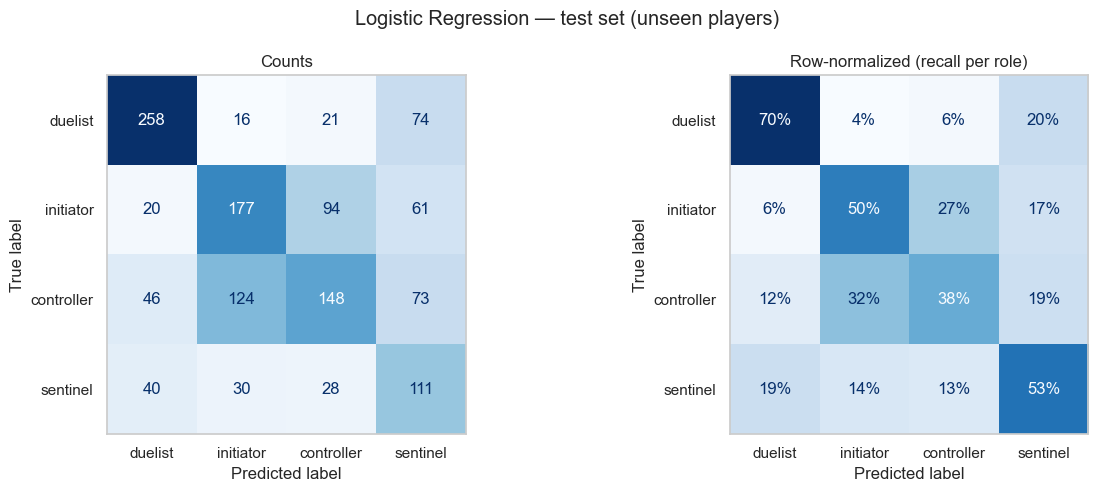

              precision    recall  f1-score   support

     duelist      0.709     0.699     0.704       369
   initiator      0.510     0.503     0.506       352
  controller      0.509     0.379     0.434       391
    sentinel      0.348     0.531     0.420       209

    accuracy                          0.525      1321
   macro avg      0.519     0.528     0.516      1321
weighted avg      0.539     0.525     0.527      1321



In [21]:
best = logreg
y_pred = best.predict(X_test)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ROLE_ORDER, cmap="Blues", ax=a1, colorbar=False)
a1.set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ROLE_ORDER, normalize="true",
                                        values_format=".0%", cmap="Blues", ax=a2, colorbar=False)
a2.set_title("Row-normalized (recall per role)")
for a in (a1, a2): a.grid(False)
plt.suptitle("Logistic Regression — test set (unseen players)")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, labels=ROLE_ORDER, digits=3))

### Which stats point to which role?

The features are scaled, so coefficients can be compared directly. Positive means more of that stat makes the role more likely.

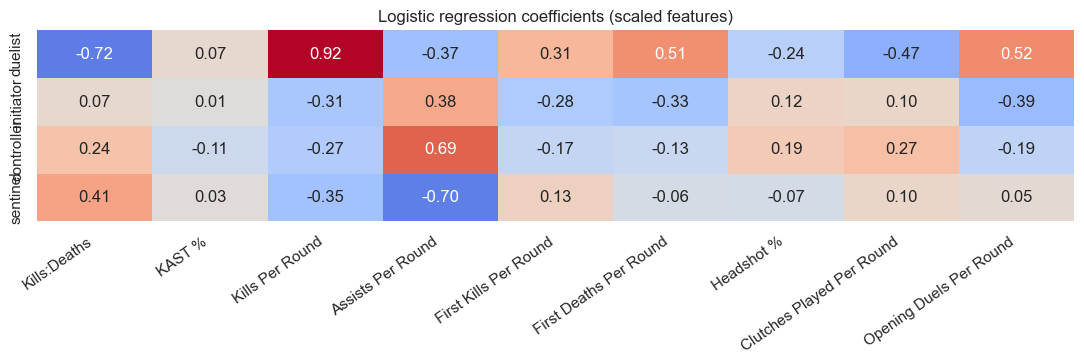

In [22]:
coefs = pd.DataFrame(best[-1].coef_, index=best[-1].classes_, columns=FEATURES).reindex(ROLE_ORDER)
stat_coefs = coefs[STAT_FEATURES]

plt.figure(figsize=(11, 3.8))
sns.heatmap(stat_coefs, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=False)
plt.title("Logistic regression coefficients (scaled features)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

In [23]:
# Average stats per role, for plain-language interpretation
data.groupby("Role")[STAT_FEATURES].mean().reindex(ROLE_ORDER).round(3)

,Kills:Deaths,KAST %,Kills Per Round,Assists Per Round,First Kills Per Round,First Deaths Per Round,Headshot %,Clutches Played Per Round,Opening Duels Per Round
Role,,,,,,,,,
duelist,1.071,69.956,0.750,0.206,0.150,0.148,27.532,0.059,0.298
initiator,0.980,71.946,0.630,0.312,0.061,0.066,28.713,0.095,0.127
controller,1.036,72.322,0.662,0.342,0.073,0.078,29.498,0.103,0.151
sentinel,1.086,69.898,0.698,0.195,0.105,0.095,28.988,0.103,0.200


## 9. Summary

### What I learned about the data

- Duelists are easy to spot, the other roles aren't. The model caught 70% of test duelists. The main sign is first-fight involvement: duelists average about 0.30 opening duels per round, double initiators and controllers. The model actually weighs first deaths more than first kills, which makes sense since dying first to make space is part of the job.
- Assists separate support roles. High assists push toward controller and initiator, away from sentinel and duelist.
- Initiators and controllers get mixed up the most: 124 controllers were predicted as initiators and 94 the other way. Both are utility roles, and the scoreboard doesn't show what kind of utility.
- Sentinels are the hardest. Their stats sit in the middle on almost everything. The model reaches 53% recall only by guessing sentinel a lot, so precision is 35%. 20% of duelists were also labeled sentinels, probably because aggressive sentinels like Chamber put up duelist-like numbers.
- Most of the variation in pro stats is about how well someone played, not their role. Clustering showed this before any model was trained.

### How effective was the model?

| Model | Test accuracy | Test macro F1 |
|---|---|---|
| Baseline (most common role) | 29.6% | 0.11 |
| Logistic Regression | 52.5% | 0.52 |
| Polynomial Logistic Regression | 51.8% | 0.50 |

- Logistic regression beats the baseline by a lot (52.5% vs. 29.6%) on players it never saw.
- Train and test accuracy are close (53.4% vs. 52.5%), so it isn't overfitting.
- The polynomial model fit training data a bit better but did slightly worse on test. The bottleneck is the features, not the model.

Bottom line: stats clearly show whether someone is an entry player, but only hint at the other roles. Separating controllers, initiators and sentinels would need utility data like smokes placed, flashes thrown, enemies revealed, or traps triggered.

### What I'd do next
- Add utility stats from round-by-round data.
- Try a Random Forest to check for nonlinear patterns.
- Predict at the map level for more (but noisier) rows.
- I looked at a round-level win/loss file from the same dataset but skipped it because its `Method` column (e.g. "Elimination" vs. "Eliminated") gives away the outcome, which would be leakage.